<a href="https://colab.research.google.com/github/PerttuKa/asos-inventory-analysis/blob/main/asosDataAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('products_asos.csv', on_bad_lines='skip')

df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
df.head()

Number of rows: 18378
Number of columns: 9


,url,name,size,category,price,color,sku,description,images
0,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
1,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
2,https://www.asos.com/asos-design/asos-design-l...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
3,https://www.asos.com/new-look/new-look-trench-...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
4,https://www.asos.com/stradivarius/stradivarius...,Stradivarius double breasted wool coat in grey,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY,123650194.0,[{'Product Details': 'Coats & Jackets by Strad...,['https://images.asos-media.com/products/strad...


In [8]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 18378 entries, 0 to 30844
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   url          18378 non-null  object 
 1   name         18378 non-null  object 
 2   size         18378 non-null  object 
 3   category     18378 non-null  object 
 4   price        18378 non-null  float64
 5   color        18378 non-null  object 
 6   sku          18378 non-null  float64
 7   description  18378 non-null  object 
 8   images       18378 non-null  object 
dtypes: float64(2), object(7)
memory usage: 1.4+ MB


,price,sku
count,18378.000000,1.837800e+04
mean,47.206741,1.190446e+08
std,35.973351,1.624541e+07
min,4.500000,4.010200e+05
25%,26.000000,1.189289e+08
50%,36.000000,1.212943e+08
75%,56.000000,1.236887e+08
max,550.000000,1.292616e+08


In [29]:
df['description'] = df['description'].astype(str)

def getBrand (text):
  if 'by ' in text:
    try:
      return text.split('by ')[1].split(' ')[0]
    except:
      return "Unknown"
  return "Unknown"

#print(getBrand(df['description'][1]))

df['brand_raw'] = df['description'].apply(getBrand)
df.head()


,url,name,size,category,price,color,sku,description,images,brand,brand_raw
0,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New
1,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New
2,https://www.asos.com/asos-design/asos-design-l...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New
3,https://www.asos.com/new-look/new-look-trench-...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New
4,https://www.asos.com/stradivarius/stradivarius...,Stradivarius double breasted wool coat in grey,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY,123650194.0,[{'Product Details': 'Coats & Jackets by Strad...,['https://images.asos-media.com/products/strad...,StradivariusJacket,StradivariusJacket


In [35]:
brand_map = {
    'New': 'New Look',
    'River': 'River Island',
    'StradivariusJacket': 'Stradivarius',
    'JDYLow-key': 'JDY',
    'TopshopWelcome': 'Topshop',
    'Miss': 'Miss Selfridge',
    'CollusionExclusive': 'Collusion'
}

df['Brand'] = df['brand_raw'].map(brand_map).fillna(df['brand_raw'])

brand_counts = df['Brand'].value_counts()
valid_brands = brand_counts[brand_counts >= 5].index
df_clean = df[df['Brand'].isin(valid_brands)].copy()

print(df_clean['Brand'].value_counts().head(5))

Brand
ASOS              4844
Topshop           1017
New Look           511
River Island       467
Miss Selfridge     429
Name: count, dtype: int64


In [36]:
def calculate_phantom_revenue(size_str):
  if not isinstance(size_str, str):
    return 0, 0.0

  sizes = size_str.split(',')
  total_sizes = len(sizes)

  out_of_stock_count = size_str.count('Out of stock')

  rate = out_of_stock_count / total_sizes if total_sizes > 0 else 0.0

  return out_of_stock_count, rate


metrics = df_clean['size'].apply(lambda x: calculate_phantom_revenue(x))
df_clean['out_of_stock_count'] = [x[0] for x in metrics]
df_clean['out_of_stock_rate'] = [x[1] for x in metrics]

df_clean['Lost_Revenue'] = df_clean['out_of_stock_count'] * df_clean['price']

cols = ['Brand', 'name', 'price', 'out_of_stock_count', 'out_of_stock_rate', 'Lost_Revenue']
print(df_clean.sort_values(by='Lost_Revenue', ascending=False)[cols].head())

                  Brand                                               name  \
2941            Barbour               Barbour Beadnell wax jacket in black   
2679   BarbourExclusive  Barbour x ASOS exclusive Stephanie wax parka i...   
21948           Topshop  Topshop premium real leather collared zip thro...   
2715               ASOS  ASOS DESIGN premium real leather trench coat i...   
15584              ASOS  ASOS EDITION geo embellished fringe plunge mid...   

       price  out_of_stock_count  out_of_stock_rate  Lost_Revenue  
2941   219.0                   9              0.900        1971.0  
2679   279.0                   7              0.875        1953.0  
21948  260.0                   7              0.875        1820.0  
2715   220.0                   7              0.875        1540.0  
15584  250.0                   6              0.750        1500.0  


/tmp/ipykernel_5472/4176174874.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


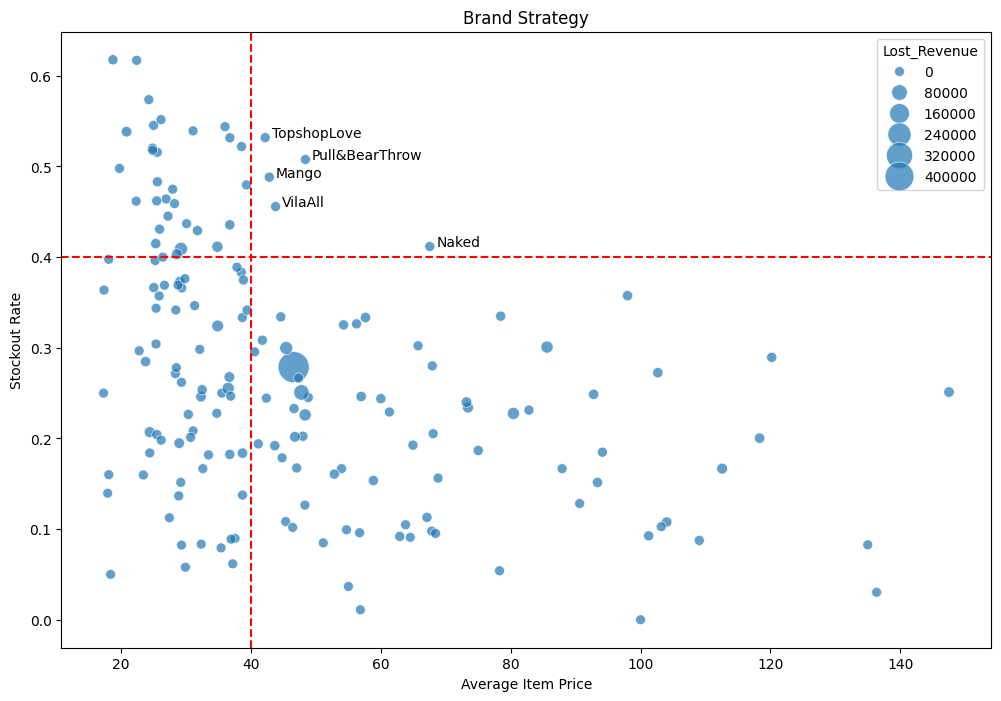

In [47]:
brand_strategy = df_clean.groupby('Brand').agg({
    'price': 'mean',
    'out_of_stock_rate': 'mean',
    'Lost_Revenue': 'sum',
    'name': 'count'
}).reset_index()

brand_strategy = brand_strategy[brand_strategy['name'] > 10]
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=brand_strategy,
    x='price',
    y='out_of_stock_rate',
    size='Lost_Revenue',
    sizes=(50, 500),
    alpha=0.7,
    palette='viridis'
)

winners = brand_strategy[
    (brand_strategy['price'] > 40) &
    (brand_strategy['out_of_stock_rate'] > 0.4)
]

for i in range(len(winners)):
  plt.text(
      winners.iloc[i]['price']+1,
      winners.iloc[i]['out_of_stock_rate'],
      winners.iloc[i]['Brand']
  )

plt.title('Brand Strategy')
plt.xlabel('Average Item Price')
plt.ylabel('Stockout Rate')
plt.axvline(x=40, color='red', linestyle='--')
plt.axhline(y=0.4, color='red', linestyle='--')
plt.show()